# Application developer effort

This experiment compares the application code required to implement agentic access control in **Baseline**, **Manual-enforcement**, and **System-enforcement**. We examine the size of the application, the code and checks associated with security, the definition of access policies, and the cyclomatic complexity of application functions.

## 1. Experimental design

The measurements use the frozen implementations and cover Python source in `apps/`, `config/`, `mcp_client/`, `mcp_server/`, and `manage.py`. Tests and migrations are excluded. The reusable `security_system/` package is outside the application developer's code scope.

The security classification covers application-specific agentic access control. Ordinary Django authentication, CSRF protection, UI ownership checks, user-scoped storage, and calls to the reusable System are excluded from this classification. They remain part of the overall application measurements.

### 1.1. Measurements

| Measurement | Meaning |
|---|---|
| Total LOC | Application-owned source lines measured with CLOC |
| Security LOC | Manually classified agentic security implementation lines |
| Security checks | Classified enforcement conditions and checks |
| Policy LOC | Classified policy definition lines, included in security LOC |
| Policies | Classified policy declarations |
| Functions | Application functions and methods measured with Radon |
| Overall CC | Sum of cyclomatic complexity scores across application functions |
| Security-related CC | Sum of full CC scores for functions overlapping classified security or policy code |

Classified LOC excludes blank lines, comments and docstrings using the measurement script's source-line procedure. Policy declarations may group restrictions differently across implementations.

### 1.2. Setup

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display

VERSIONS = ["v1", "v2", "v3"]
LABELS = {"v1": "Baseline", "v2": "Manual-enforcement", "v3": "System-enforcement"}
COLORS = {"v1": "#64748b", "v2": "#15877f", "v3": "#c47f36"}
PAIRS = [("v2", "v1", "Manual vs Baseline"), ("v3", "v1", "System vs Baseline"), ("v3", "v2", "System vs Manual")]
PAIR_COLORS = {"Manual vs Baseline": COLORS["v2"], "System vs Baseline": COLORS["v3"], "System vs Manual": "#7764a6"}

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results/developer_effort").is_dir()), None)

if ROOT is None:
    raise FileNotFoundError("Could not find results/developer_effort")

RESULTS = ROOT / "results/developer_effort"
OUTPUT = RESULTS / "analysis"
FIGURES = OUTPUT / "figures"
TABLES = OUTPUT / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 115, "savefig.dpi": 300,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})

### 1.3. Load and verify the measurements

In [41]:
comparison = pd.read_csv(RESULTS / "comparison.csv").set_index("metric")[VERSIONS]
differences = pd.read_csv(RESULTS / "differences.csv").set_index("metric")
complexity = pd.read_csv(RESULTS / "complexity.csv")

components = ["Application LOC", "MCP client LOC", "MCP server LOC"]

assert comparison.index.is_unique and differences.index.is_unique
assert set(comparison.index) == set(differences.index)
assert np.isfinite(comparison.to_numpy()).all() and comparison.ge(0).all().all()
assert comparison.mod(1).eq(0).all().all()
assert comparison.loc[components].sum().eq(comparison.loc["Total LOC"]).all()
assert comparison.loc["Application policy LOC"].le(comparison.loc["Application security LOC"]).all()
assert comparison.loc["Application security LOC"].le(comparison.loc["Total LOC"]).all()

assert set(complexity["version"]) == set(VERSIONS)
assert not complexity.duplicated(["version", "file", "line"]).any()
assert not complexity.isna().any().any()
assert complexity["security_related"].isin([0, 1]).all()
assert complexity["complexity"].ge(1).all() and complexity["complexity"].mod(1).eq(0).all()
assert complexity["grade"].eq(pd.cut(complexity["complexity"], [0, 5, 10, 20, 30, 40, np.inf], labels=list("ABCDEF")).astype("object")).all()

for version, reference, _ in PAIRS:
    delta = comparison[version] - comparison[reference]
    assert delta.eq(differences.loc[comparison.index, f"{version.upper()} - {reference.upper()}"]).all()
    pct = (100 * delta / comparison[reference].replace(0, np.nan)).round(1)
    assert np.allclose(pct, differences.loc[comparison.index, f"{version.upper()} vs {reference.upper()} (%)"], equal_nan=True)

print(f"{len(comparison)} source metrics | {len(complexity)} function records verified")

8 source metrics | 203 function records verified


In [42]:
classification_path = ROOT / "experiments/developer_effort/classification.csv" if ROOT else RESULTS / "classification.csv"
if classification_path.is_file():
    classification = pd.read_csv(classification_path)
    assert set(classification["version"]).issubset(VERSIONS)
    assert classification["start"].ge(1).all() and classification["end"].ge(classification["start"]).all()
    for version in VERSIONS:
        rows = classification[classification["version"].eq(version)]
        assert rows["kind"].eq("security_check").sum() == comparison.loc["Security checks (count)", version]
        assert rows["kind"].eq("policy").sum() == comparison.loc["Policies (count)", version]
        lines = {kind: {(r.file, line) for r in rows[rows["kind"].eq(kind)].itertuples() for line in range(r.start, r.end + 1)} for kind in ["security_code", "policy_code"]}
        assert lines["policy_code"].issubset(lines["security_code"])
    print("Classification counts and policy ranges verified")
else:
    print("Classification file unavailable")

Classification counts and policy ranges verified


In [43]:
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_table(data):
    display(data.rename(columns=LABELS, index=LABELS).round(2).fillna("N/A"))


def style_axis(ax, title, axis="y"):
    ax.set_title(title, loc="left", fontsize=13, pad=15)
    ax.grid(axis=axis, alpha=.16)
    ax.set_axisbelow(True)


def grouped_bars(data, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    x, width = np.arange(len(data)), .24
    for i, version in enumerate(VERSIONS):
        bars = ax.bar(x + (i - 1) * width, data[version], width, color=COLORS[version], label=LABELS[version])
        ax.bar_label(bars, labels=[f"{value:g}" if value else "" for value in data[version]], padding=3, fontsize=9)
    ax.set_xticks(x, data.index)
    ax.set(ylabel=ylabel, ylim=(0, max(1, data.max().max()) * 1.20))
    style_axis(ax, title)
    ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.16))
    show_figure(fig, filename)


def version_bars(values, title, ylabel, filename, decimals=0):
    fig, ax = plt.subplots(figsize=(8.7, 4.5))
    for i, version in enumerate(VERSIONS):
        value = values[version]
        if pd.isna(value):
            ax.text(i, 0, "N/A", ha="center", va="bottom", color="#64748b")
        else:
            bars = ax.bar(i, value, width=.55, color=COLORS[version])
            ax.bar_label(bars, labels=[f"{value:,.{decimals}f}" if value else ""], padding=4)
    ax.set_xticks(range(3), [LABELS[v] for v in VERSIONS])
    ax.set(ylabel=ylabel, ylim=(0, max(1, values.max()) * 1.20))
    style_axis(ax, title)
    show_figure(fig, filename)


## 2. Lines of code (LOC)

We first compare the size of the application-owned source, then examine how the code is distributed across its components.

### 2.1. Total LOC

In [44]:
show_table(comparison.loc[["Total LOC"]])

,Baseline,Manual-enforcement,System-enforcement
metric,,,
Total LOC,651,1467,709


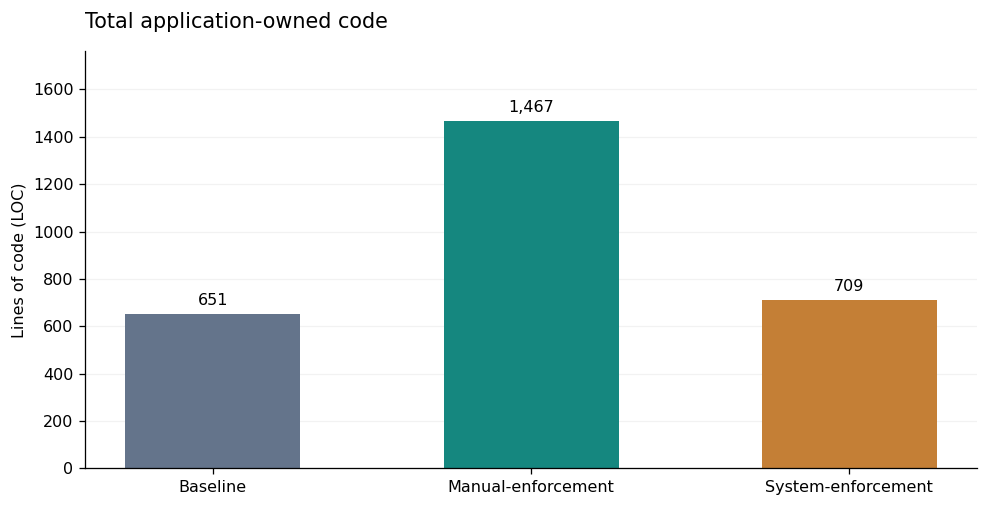

In [45]:
version_bars(comparison.loc["Total LOC"], "Total application-owned code", "Lines of code (LOC)", "01_total_loc.png")

Manual-enforcement contains 1,467 LOC, compared with 651 in Baseline and 709 in System-enforcement.

### 2.2. LOC by component

In [46]:
show_table(comparison.loc[components])

,Baseline,Manual-enforcement,System-enforcement
metric,,,
Application LOC,452,1161,522
MCP client LOC,99,186,103
MCP server LOC,100,120,84


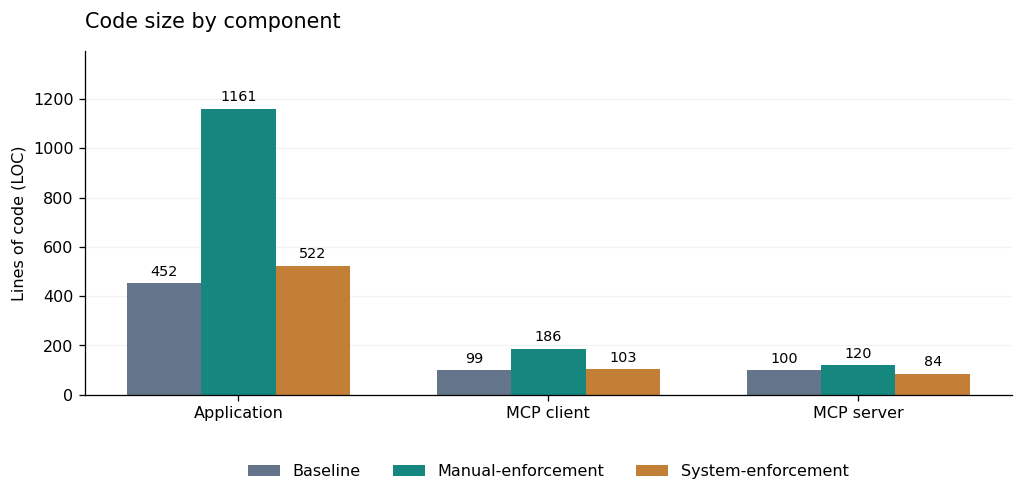

In [47]:
data = comparison.loc[components].rename(index=lambda x: x.replace(" LOC", ""))
grouped_bars(data, "Code size by component", "Lines of code (LOC)", "02_component_loc.png")

Most of the code added in Manual-enforcement is in the application component. The MCP client and server also contain additional code.

## 3. Security implementation

The total LOC includes both ordinary application functionality and agentic access control. We examine the classified security lines and enforcement checks separately to determine how much of the application implements security.

### 3.1. Security LOC

The security share is calculated relative to the total application-owned LOC of each implementation.

In [48]:
security_share = 100 * comparison.loc["Application security LOC"] / comparison.loc["Total LOC"]
show_table(pd.DataFrame([comparison.loc["Application security LOC"], comparison.loc["Total LOC"], security_share], index=["Security LOC", "Total LOC", "Security share (%)"]))

,Baseline,Manual-enforcement,System-enforcement
Security LOC,0.0,851.00,63.00
Total LOC,651.0,1467.00,709.00
Security share (%),0.0,58.01,8.89


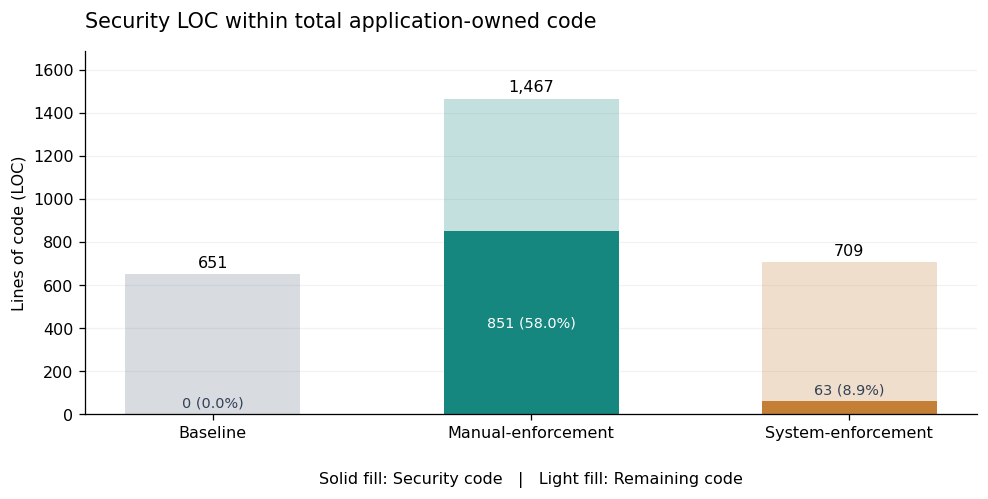

In [49]:
fig, ax = plt.subplots(figsize=(8.7, 4.5))
for i, version in enumerate(VERSIONS):
    total = comparison.loc["Total LOC", version]
    security_loc = comparison.loc["Application security LOC", version]
    ax.bar(i, total, width=.55, color=COLORS[version], alpha=.25)
    ax.bar(i, security_loc, width=.55, color=COLORS[version])
    ax.text(i, total + 30, f"{total:,}", ha="center")
    ax.text(i, security_loc / 2 if security_loc > 150 else security_loc + 18, f"{security_loc:,} ({security_share[version]:.1f}%)", ha="center", va="center" if security_loc > 150 else "bottom", color="white" if security_loc > 150 else "#334155", fontsize=9)
ax.set_xticks(range(3), [LABELS[v] for v in VERSIONS])
ax.set(ylabel="Lines of code (LOC)", ylim=(0, comparison.loc["Total LOC"].max() * 1.15))
style_axis(ax, "Security LOC within total application-owned code")
ax.text(.5, -.19, "Solid fill: Security code   |   Light fill: Remaining code", transform=ax.transAxes, ha="center", fontsize=10)
show_figure(fig, "03_security_loc.png")

Manual-enforcement contains 851 security LOC, representing 58.0% of its total code. System-enforcement contains 63 security LOC (8.9%).

### 3.2. Security checks

In [50]:
show_table(comparison.loc[["Security checks (count)"]])

,Baseline,Manual-enforcement,System-enforcement
metric,,,
Security checks (count),0,70,7


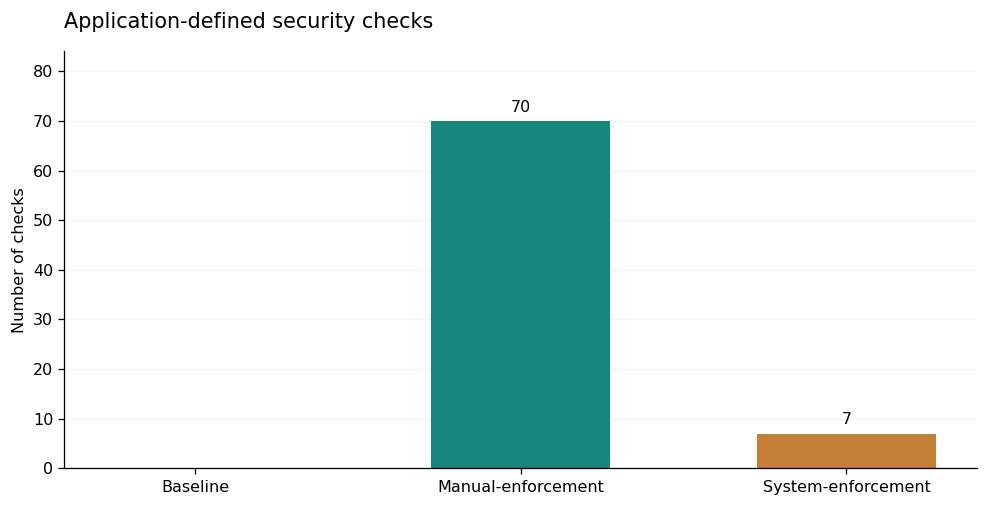

In [51]:
version_bars(comparison.loc["Security checks (count)"], "Application-defined security checks", "Number of checks", "04_security_checks.png")

Manual-enforcement contains 70 application-defined security checks, compared with seven in System-enforcement. The counts refer to checks within the application source scope.

## 4. Policy definitions

Policy definitions are a subset of the classified security code. We examine their size and number before separating policy code from the remaining enforcement code.

### 4.1. Policy LOC

In [52]:
show_table(comparison.loc[["Application policy LOC"]])

,Baseline,Manual-enforcement,System-enforcement
metric,,,
Application policy LOC,0,159,49


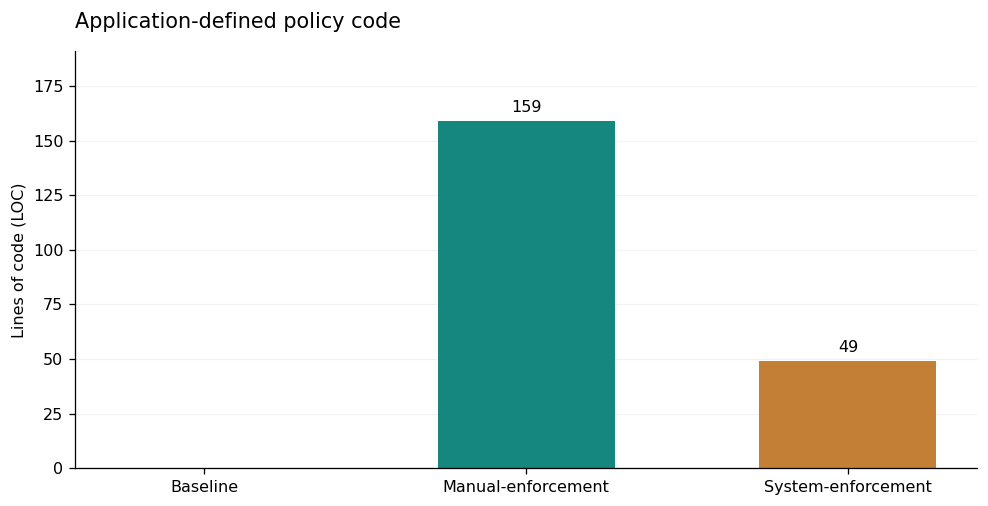

In [53]:
version_bars(comparison.loc["Application policy LOC"], "Application-defined policy code", "Lines of code (LOC)", "05_policy_loc.png")

Manual-enforcement contains 159 policy LOC, while System-enforcement contains 49.

### 4.2. Policy declarations

In [54]:
show_table(comparison.loc[["Policies (count)"]])

,Baseline,Manual-enforcement,System-enforcement
metric,,,
Policies (count),0,10,5


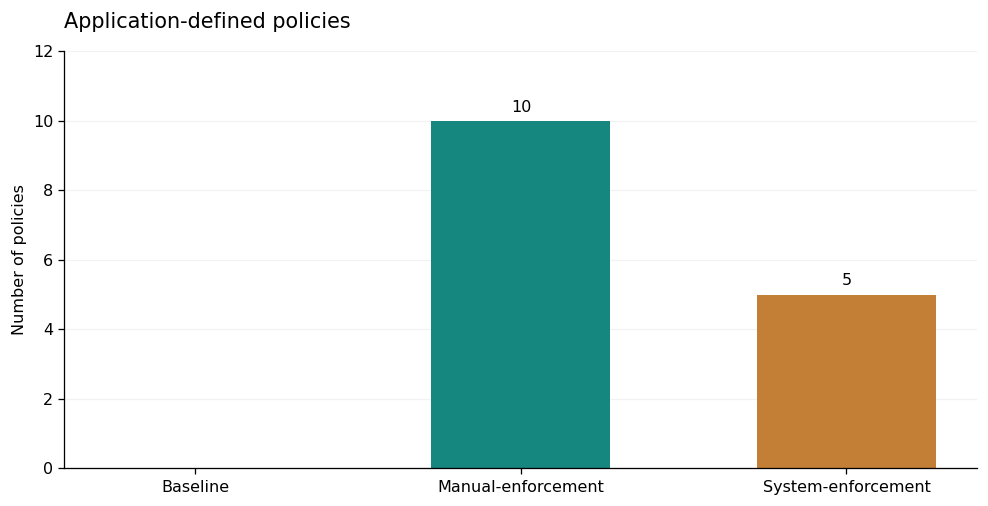

In [55]:
version_bars(comparison.loc["Policies (count)"], "Application-defined policies", "Number of policies", "06_policy_count.png")

Manual-enforcement defines ten policies and System-enforcement defines five. The declarations group access restrictions differently across implementations.

### 4.3. Security and policy code composition

Policy LOC is included in security LOC. The three categories partition the total application-owned code, including the MCP client and server. The table retains both line counts and percentages.

In [56]:
composition = pd.DataFrame({"Policy code": comparison.loc["Application policy LOC"],
                            "Other security code": comparison.loc["Application security LOC"] - comparison.loc["Application policy LOC"],
                            "Remaining code": comparison.loc["Total LOC"] - comparison.loc["Application security LOC"]})
assert composition.sum(axis=1).eq(comparison.loc["Total LOC"]).all()
shares = composition.div(comparison.loc["Total LOC"], axis=0) * 100
show_table(composition)
show_table(shares.rename_axis("Share of total LOC (%)"))

,Policy code,Other security code,Remaining code
Baseline,0,0,651
Manual-enforcement,159,692,616
System-enforcement,49,14,646


,Policy code,Other security code,Remaining code
Share of total LOC (%),,,
Baseline,0.00,0.00,100.00
Manual-enforcement,10.84,47.17,41.99
System-enforcement,6.91,1.97,91.11


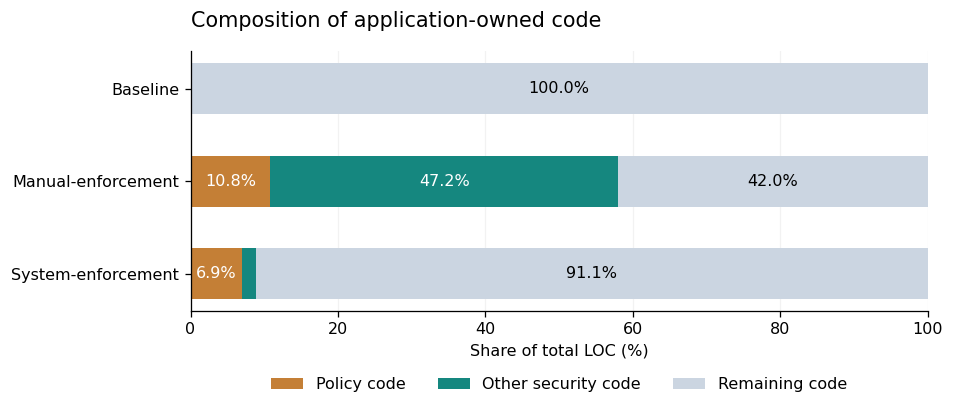

In [57]:
fig, ax = plt.subplots(figsize=(8.4, 3.8))
left = np.zeros(3)
for category, color in zip(shares.columns, ["#c47f36", "#15877f", "#cbd5e1"]):
    values = shares[category].to_numpy()
    ax.barh([LABELS[v] for v in VERSIONS], values, left=left, color=color, label=category, height=.55)
    for i, (start, value) in enumerate(zip(left, values)):
        if value >= 6:
            ax.text(start + value / 2, i, f"{value:.1f}%", ha="center", va="center", color="black" if category == "Remaining code" else "white")
    left += values
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Share of total LOC (%)")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.20), ncol=3, frameon=False)
style_axis(ax, "Composition of application-owned code", axis="x")
show_figure(fig, "07_code_composition.png")

Other security code decreases from 692 LOC to 14 LOC. In System-enforcement, 49 of the 63 classified security lines (77.8%) define application policies, compared with 159 of 851 (18.7%) in Manual-enforcement. Relative to total LOC, policy code accounts for 10.8% in Manual-enforcement and 6.9% in System-enforcement.

## 5. Cyclomatic complexity

Cyclomatic complexity (CC) measures independent control-flow paths through a function. A straight-line function has CC = 1. Branches, loops, exception handlers and Boolean operations may increase the score. We first examine the number of functions and their combined and mean complexity, then investigate the distribution of scores and the contribution of security-related functions.

### 5.1. Overall complexity

Total CC depends on both the number of functions and the complexity of each function. The following table and figures examine these quantities together.

In [58]:
def summarize_cc(data):
    summary = data.groupby("version")["complexity"].agg(functions="count", total_cc="sum", mean_cc="mean", median_cc="median", max_cc="max").reindex(VERSIONS)
    summary[["functions", "total_cc"]] = summary[["functions", "total_cc"]].fillna(0).astype(int)
    return summary


overall = summarize_cc(complexity)
security = summarize_cc(complexity[complexity["security_related"].eq(1)])
other = summarize_cc(complexity[complexity["security_related"].eq(0)])
assert (security[["functions", "total_cc"]] + other[["functions", "total_cc"]]).eq(overall[["functions", "total_cc"]]).all().all()

In [59]:
cc_labels = {"functions": "Functions", "total_cc": "Total CC", "mean_cc": "Mean CC", "median_cc": "Median CC", "max_cc": "Maximum CC"}
show_table(overall.T.rename(index=cc_labels))

version,Baseline,Manual-enforcement,System-enforcement
Functions,54.00,88.00,61.00
Total CC,101.00,310.00,109.00
Mean CC,1.87,3.52,1.79
Median CC,1.00,2.00,1.00
Maximum CC,9.00,45.00,10.00


#### Function count and mean complexity

Function count measures the number of application-defined functions and methods. Mean CC divides total CC by that count.

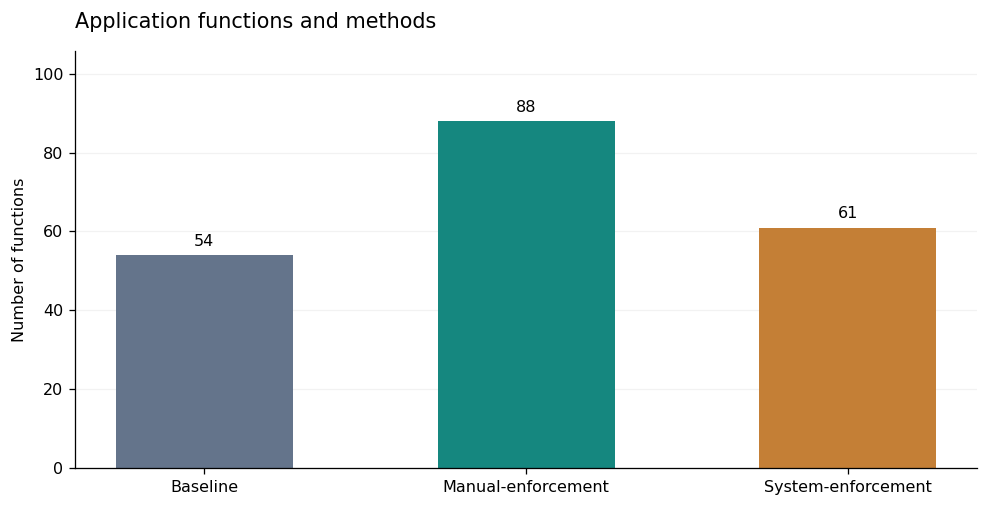

In [60]:
version_bars(overall["functions"], "Application functions and methods", "Number of functions", "08_function_count.png")

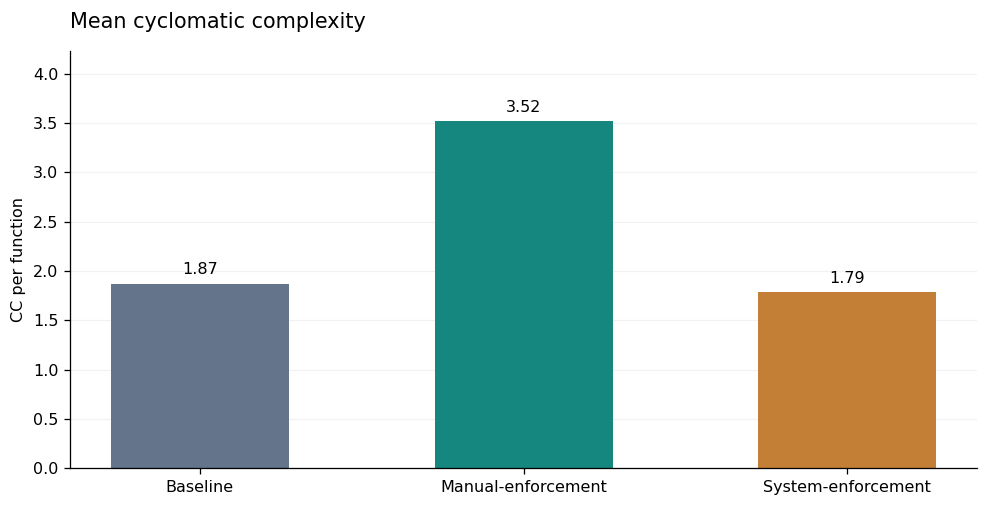

In [61]:
version_bars(overall["mean_cc"], "Mean cyclomatic complexity", "CC per function", "09_mean_cc.png", decimals=2)

Manual-enforcement contains more functions (88) than Baseline (54) and System-enforcement (61). Its mean CC is also higher (3.52 compared with 1.87 and 1.79).

The median scores are 1, 2 and 1, respectively. The distribution below provides further detail on the variation between individual functions.

### 5.2. Complexity by component

We divide the overall CC by source component to identify where the additional control-flow complexity occurs.

In [62]:
complexity["component"] = np.select([complexity["file"].str.startswith("mcp_client/"), complexity["file"].str.startswith("mcp_server/")], ["MCP client", "MCP server"], default="Application")
component_cc = complexity.pivot_table(index="component", columns="version", values="complexity", aggfunc="sum", fill_value=0).reindex(["Application", "MCP client", "MCP server"], fill_value=0)[VERSIONS]
assert component_cc.sum().eq(overall["total_cc"]).all()
show_table(component_cc)

version,Baseline,Manual-enforcement,System-enforcement
component,,,
Application,44,217,56
MCP client,27,58,29
MCP server,30,35,24


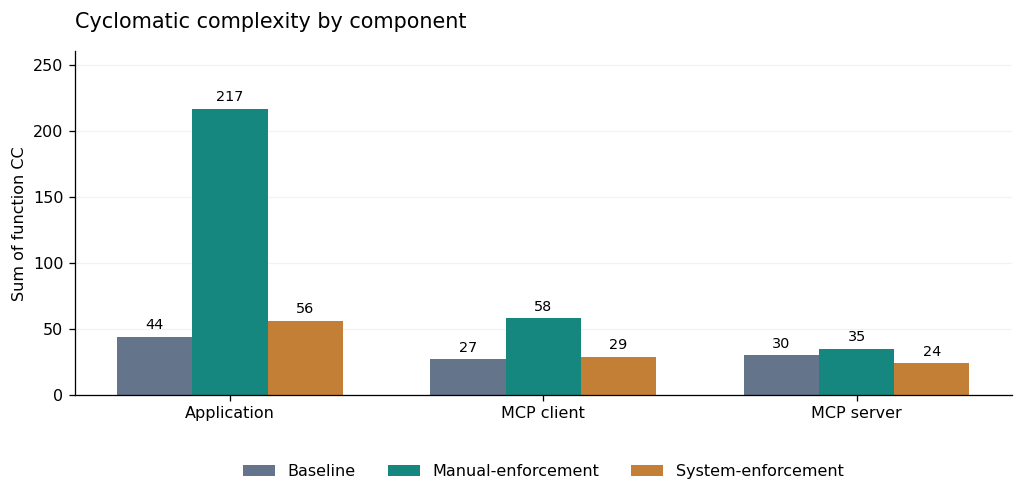

In [63]:
grouped_bars(component_cc, "Cyclomatic complexity by component", "Sum of function CC", "10_component_cc.png")

The application component accounts for 173 of the 209 additional CC points in Manual-enforcement relative to Baseline. System-enforcement reduces the combined complexity in all three components relative to Manual-enforcement.

### 5.3. Complexity grade distribution

Radon groups function scores into six [grades](https://radon.readthedocs.io/en/master/commandline.html#the-cc-command).

| Grade | CC range | Radon interpretation |
|---|---:|---|
| A | 1–5 | Low risk, simple block |
| B | 6–10 | Low risk, structured block |
| C | 11–20 | Moderate risk |
| D | 21–30 | Moderate risk, more complex block |
| E | 31–40 | High risk |
| F | 41+ | Very high risk |

The grades describe control-flow complexity rather than the correctness of a function.

In [64]:
grades = list("ABCDEF")
grade_counts = pd.crosstab(complexity["grade"], complexity["version"]).reindex(index=grades, columns=VERSIONS, fill_value=0)
assert grade_counts.sum().eq(overall["functions"]).all()
grade_shares = grade_counts.div(overall["functions"], axis=1) * 100
show_table(grade_counts.rename_axis("Grade"))
show_table(grade_shares.round(1).rename_axis("Grade (%)"))

version,Baseline,Manual-enforcement,System-enforcement
Grade,,,
A,52,77,59
B,2,6,2
C,0,4,0
D,0,0,0
E,0,0,0
F,0,1,0


version,Baseline,Manual-enforcement,System-enforcement
Grade (%),,,
A,96.3,87.5,96.7
B,3.7,6.8,3.3
C,0.0,4.5,0.0
D,0.0,0.0,0.0
E,0.0,0.0,0.0
F,0.0,1.1,0.0


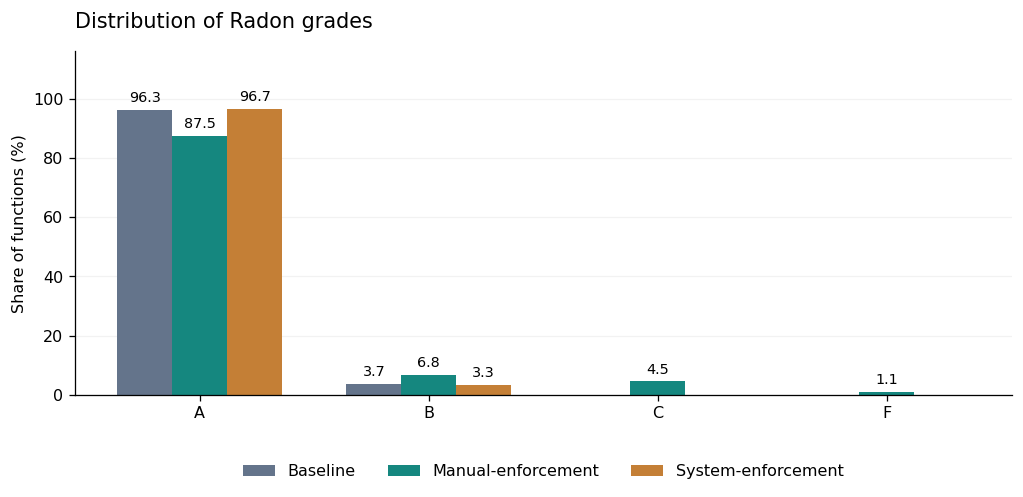

In [65]:
data = grade_shares.loc[grade_counts.sum(axis=1).gt(0)].round(1)
grouped_bars(data, "Distribution of Radon grades", "Share of functions (%)", "11_complexity_grades.png")

Most functions receive grade A in each implementation. Manual-enforcement contains four grade C functions and one grade F function. Baseline and System-enforcement contain only grades A and B. The percentages account for differences in function counts.

#### Function complexity distribution

Each point represents a function score. Horizontal lines indicate the median; a fixed jitter separates observations with the same score.

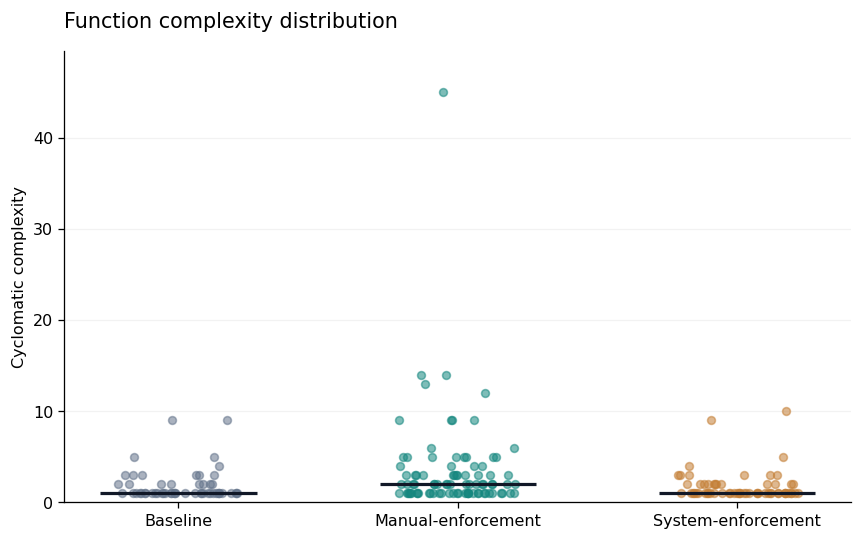

In [66]:
fig, ax = plt.subplots(figsize=(7.6, 4.8))
rng = np.random.default_rng(42)
for i, v in enumerate(VERSIONS):
    values = complexity.loc[complexity["version"].eq(v), "complexity"].to_numpy()
    ax.scatter(i + rng.uniform(-.22, .22, len(values)), values, color=COLORS[v], alpha=.55, s=24)
    ax.hlines(np.median(values), i - .28, i + .28, color="#111827", linewidth=2)
ax.set_xticks(range(3), [LABELS[v] for v in VERSIONS])
ax.set(ylabel="Cyclomatic complexity", ylim=(0, complexity["complexity"].max() * 1.1))
style_axis(ax, "Function complexity distribution")
show_figure(fig, "12_complexity_distribution.png")

Manual-enforcement has the widest range of function scores, with a maximum CC of 45. The maximum scores of Baseline and System-enforcement are 9 and 10.

### 5.4. Security-related complexity

The preceding results cover all application functions. To examine the contribution of security implementation, we separate functions whose source range overlaps classified security or policy code from the other functions. Each classified function contributes its full CC. Baseline has no classified security-related functions, so its mean, median and maximum for this group are undefined.

In [67]:
show_table(security.T.rename(index=cc_labels).rename_axis("Security-related functions"))
show_table(other.T.rename(index=cc_labels).rename_axis("Other functions"))

version,Baseline,Manual-enforcement,System-enforcement
Security-related functions,,,
Functions,0.0,53.00,5.0
Total CC,0.0,245.00,11.0
Mean CC,N/A,4.62,2.2
Median CC,N/A,3.00,2.0
Maximum CC,N/A,45.00,3.0


version,Baseline,Manual-enforcement,System-enforcement
Other functions,,,
Functions,54.00,35.00,56.00
Total CC,101.00,65.00,98.00
Mean CC,1.87,1.86,1.75
Median CC,1.00,1.00,1.00
Maximum CC,9.00,9.00,10.00


#### Contribution to total complexity

The stacked bars show how the total CC is divided between classified security-related functions and the remaining functions.

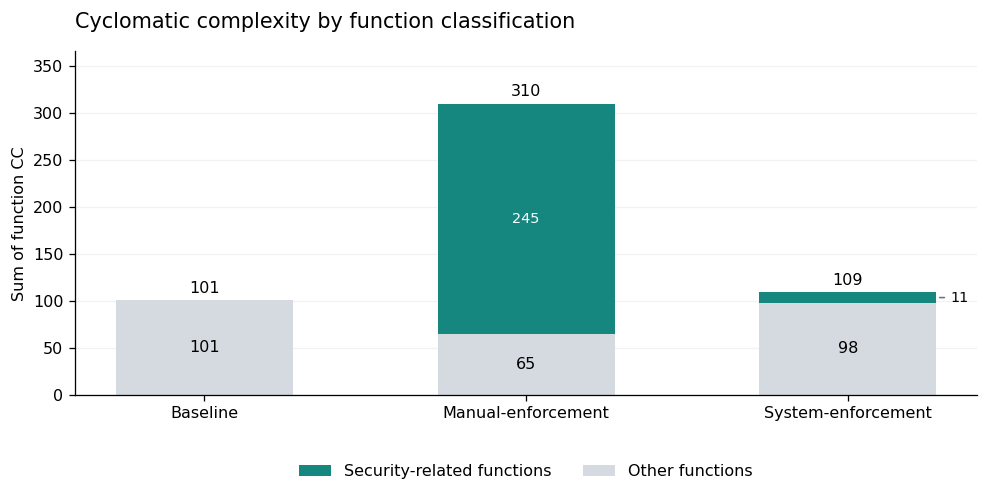

In [68]:
fig, ax = plt.subplots(figsize=(8.7, 4.5))
for i, version in enumerate(VERSIONS):
    non_security = other.loc[version, "total_cc"]
    security_cc = security.loc[version, "total_cc"]
    ax.bar(i, non_security, width=.55, color="#D5DAE1")
    ax.bar(i, security_cc, width=.55, bottom=non_security, color="#15877f")
    ax.text(i, non_security / 2, f"{non_security:g}", ha="center", va="center", fontsize=10)
    if security_cc >= 25:
        ax.text(i, non_security + security_cc / 2, f"{security_cc:g}", ha="center", va="center", color="white", fontsize=9)
    elif security_cc:
        ax.annotate(f"{security_cc:g}", (i + .275, non_security + security_cc / 2), xytext=(9, 0), textcoords="offset points", va="center", fontsize=9, arrowprops={"arrowstyle": "-", "color": "#64748b"})
    ax.text(i, non_security + security_cc + 8, f"{overall.loc[version, 'total_cc']:g}", ha="center")
ax.set_xticks(range(3), [LABELS[v] for v in VERSIONS])
ax.set(ylabel="Sum of function CC", ylim=(0, overall["total_cc"].max() * 1.18))
style_axis(ax, "Cyclomatic complexity by function classification")
ax.legend(handles=[Patch(facecolor="#15877f", label="Security-related functions"), Patch(facecolor="#D5DAE1", label="Other functions")], frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.16))
show_figure(fig, "13_overall_cc.png")

#### Total and mean security-related complexity

Total CC measures the combined complexity of the classified functions. Mean CC accounts for the number of functions in that group.

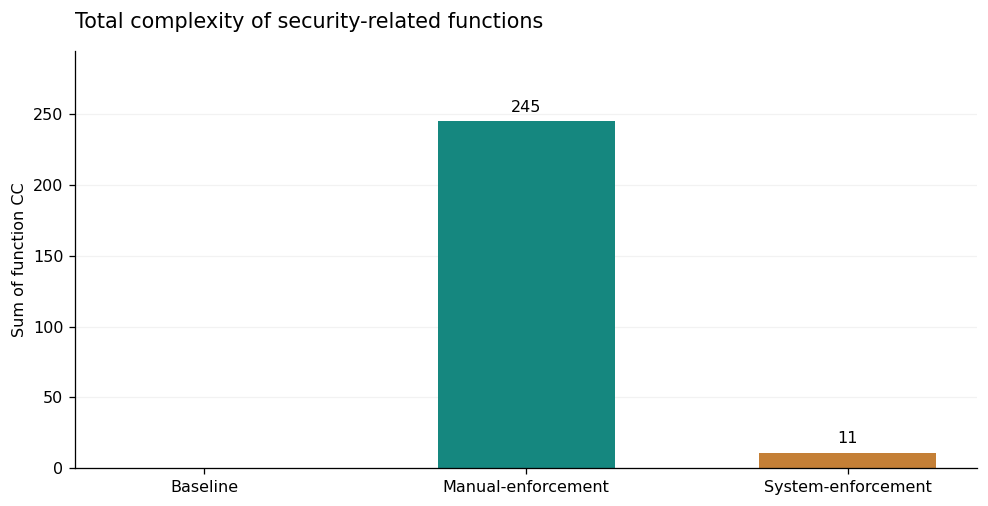

In [69]:
version_bars(security["total_cc"], "Total complexity of security-related functions", "Sum of function CC", "14_security_cc.png")

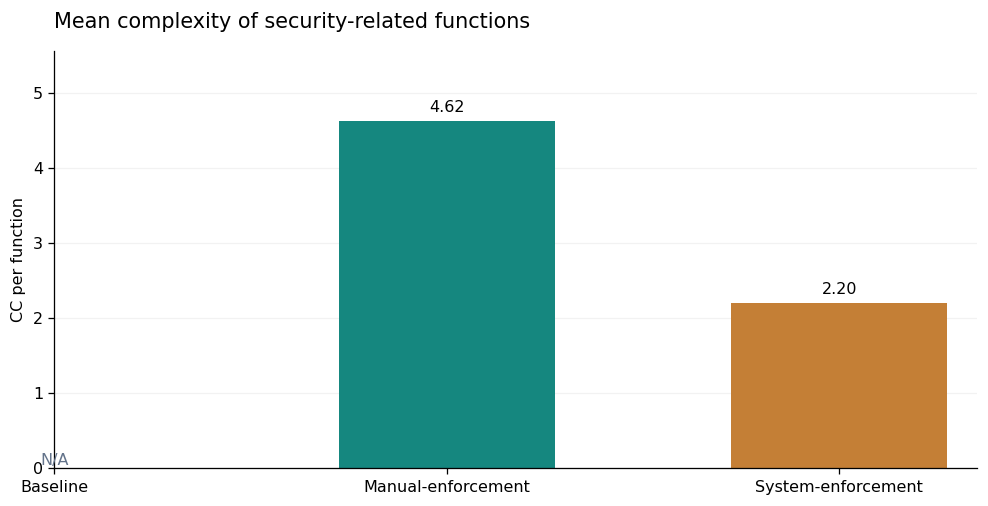

In [70]:
version_bars(security["mean_cc"], "Mean complexity of security-related functions", "CC per function", "15_security_mean_cc.png", decimals=2)

Manual-enforcement contains 53 security-related functions with total CC of 245. System-enforcement contains five with total CC of 11. The mean CC of functions without classified security code is similar across implementations (1.87, 1.86 and 1.75). The higher combined complexity in Manual-enforcement is therefore concentrated in the classified functions.

### 5.5. Functions with the highest complexity

The highest-scoring functions identify the specific operations contributing to the upper end of the complexity distribution.

In [71]:
top = complexity.sort_values(["version", "complexity", "file", "line"], ascending=[True, False, True, True]).groupby("version", sort=False).head(5)
display(top.assign(version=top["version"].map(LABELS))[['version', 'file', 'function', 'complexity', 'grade', 'security_related']].reset_index(drop=True))

,version,file,function,complexity,grade,security_related
0,Baseline,apps/agents/service.py,run_agent,9,B,0
1,Baseline,mcp_client/client.py,_extract_text,9,B,0
2,Baseline,mcp_server/tools/files.py,search_files_impl,5,A,0
3,Baseline,mcp_server/tools/sql.py,execute_sql_impl,5,A,0
4,Baseline,apps/files/views.py,file_upload,4,A,0
5,Manual-enforcement,apps/authorization/sql_validation.py,inspect_sql,45,F,1
6,Manual-enforcement,apps/agents/service.py,run_agent,14,C,1
7,Manual-enforcement,mcp_client/path_helpers.py,normalize_user_file_path,14,C,1
8,Manual-enforcement,apps/agents/side_effects.py,confirm_pending_side_effect,13,C,1
9,Manual-enforcement,apps/authorization/policies.py,validate_policies,12,C,1


The highest-scoring Manual-enforcement function is `inspect_sql` (CC 45), followed by `run_agent` and `normalize_user_file_path` (CC 14 each). `confirm_pending_side_effect` (CC 13), and validate_policies (CC 12). In Baseline and System-enforcement, the maximum scores are 9 and 10, respectively.

## 6. Differences between implementations

The comparisons report changes relative to Baseline and the difference between the two secured implementations. Absolute changes are calculated as the first implementation minus the reference. Percentage changes use the reference value as the denominator; a zero reference gives N/A.

In [72]:
metrics = pd.DataFrame({
    "Total LOC": comparison.loc["Total LOC"],
    "Security LOC": comparison.loc["Application security LOC"],
    "Security checks": comparison.loc["Security checks (count)"],
    "Policy LOC": comparison.loc["Application policy LOC"],
    "Policies": comparison.loc["Policies (count)"],
    "Functions": overall["functions"],
    "Overall CC": overall["total_cc"],
    "Security-related CC": security["total_cc"]
}).T
absolute = pd.DataFrame({label: metrics[a] - metrics[b] for a, b, label in PAIRS})
relative = pd.DataFrame({label: 100 * absolute[label] / metrics[b].replace(0, np.nan) for a, b, label in PAIRS})
show_table(metrics)
display(absolute.rename_axis("Absolute change"))
display(relative.round(1).fillna("N/A").rename_axis("Percentage change (%)"))

,Baseline,Manual-enforcement,System-enforcement
Total LOC,651,1467,709
Security LOC,0,851,63
Security checks,0,70,7
Policy LOC,0,159,49
Policies,0,10,5
Functions,54,88,61
Overall CC,101,310,109
Security-related CC,0,245,11


,Manual vs Baseline,System vs Baseline,System vs Manual
Absolute change,,,
Total LOC,816,58,-758
Security LOC,851,63,-788
Security checks,70,7,-63
Policy LOC,159,49,-110
Policies,10,5,-5
Functions,34,7,-27
Overall CC,209,8,-201
Security-related CC,245,11,-234


,Manual vs Baseline,System vs Baseline,System vs Manual
Percentage change (%),,,
Total LOC,125.3,8.9,-51.7
Security LOC,N/A,N/A,-92.6
Security checks,N/A,N/A,-90.0
Policy LOC,N/A,N/A,-69.2
Policies,N/A,N/A,-50.0
Functions,63.0,13.0,-30.7
Overall CC,206.9,7.9,-64.8
Security-related CC,N/A,N/A,-95.5


### 6.1. Additional code and complexity relative to Baseline

Total LOC and overall CC have nonzero baseline values. Their relative changes show the additional application size and combined complexity associated with the two secured implementations.

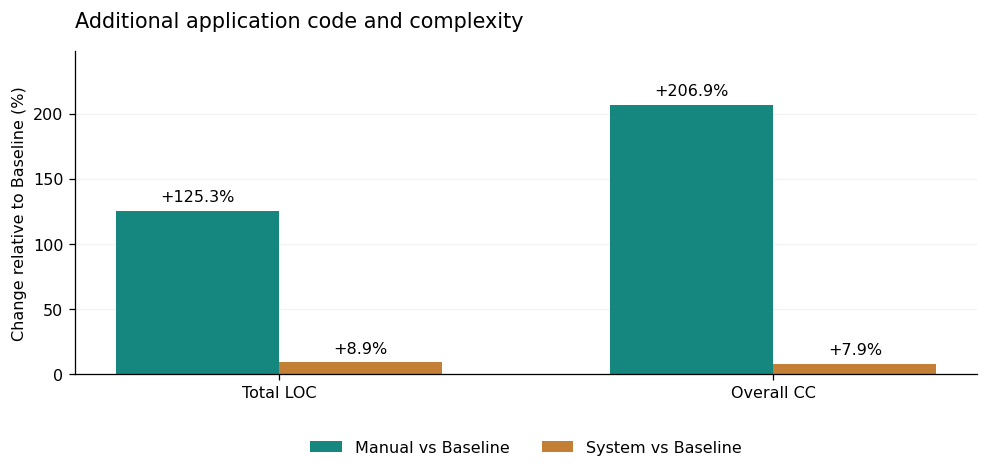

In [73]:
data = relative.loc[["Total LOC", "Overall CC"], ["Manual vs Baseline", "System vs Baseline"]]
fig, ax = plt.subplots(figsize=(8.7, 4.3))
x, width = np.arange(len(data)), .33
for i, label in enumerate(data.columns):
    bars = ax.bar(x + (i - .5) * width, data[label], width, color=PAIR_COLORS[label], label=label)
    ax.bar_label(bars, labels=[f"{value:+.1f}%" for value in data[label]], padding=4)
ax.set_xticks(x, data.index)
ax.set(ylabel="Change relative to Baseline (%)", ylim=(0, data.max().max() * 1.20))
style_axis(ax, "Additional application code and complexity")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.16))
show_figure(fig, "16_baseline_differences.png")

Manual-enforcement increases total LOC by 125.3% and overall CC by 206.9%. The corresponding increases for System-enforcement are 8.9% and 7.9%.

### 6.2. Reduction relative to Manual-enforcement

The following comparison uses Manual-enforcement as the reference for all eight measurements. A positive percentage indicates a reduction in System-enforcement.

In [74]:
reduction = -relative["System vs Manual"]
display(metrics[["v2", "v3"]].rename(columns=LABELS).assign(**{"Reduction (%)": reduction}).round(1))

,Manual-enforcement,System-enforcement,Reduction (%)
Total LOC,1467,709,51.7
Security LOC,851,63,92.6
Security checks,70,7,90.0
Policy LOC,159,49,69.2
Policies,10,5,50.0
Functions,88,61,30.7
Overall CC,310,109,64.8
Security-related CC,245,11,95.5


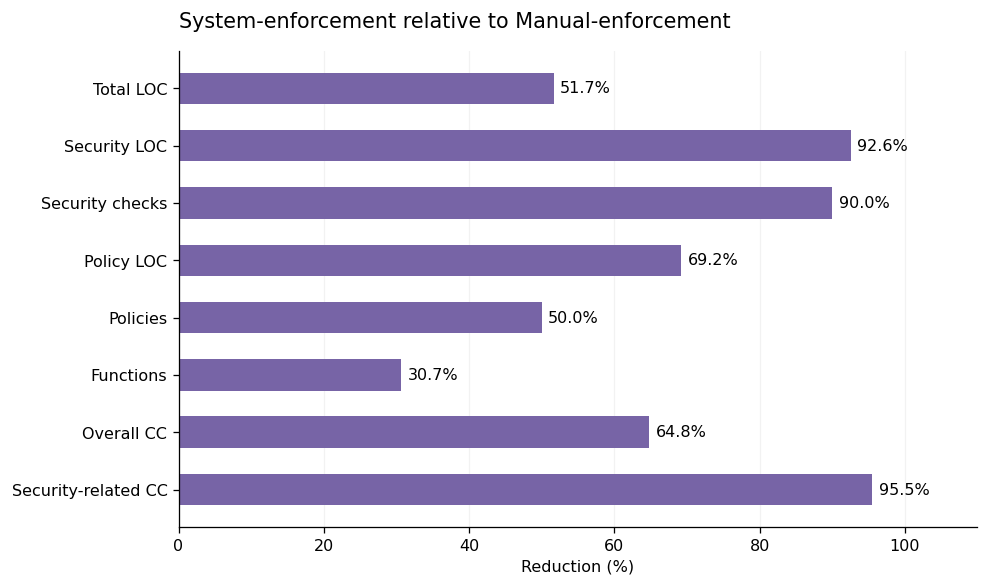

In [75]:
fig, ax = plt.subplots(figsize=(8.7, 5.2))
bars = ax.barh(reduction.index, reduction, color=PAIR_COLORS["System vs Manual"], height=.55)
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in reduction], padding=4)
ax.invert_yaxis()
ax.set(xlabel="Reduction (%)", xlim=(0, 110))
style_axis(ax, "System-enforcement relative to Manual-enforcement", axis="x")
show_figure(fig, "17_system_vs_manual.png")

### 6.3. Component and function-level differences

The detailed comparisons retain changes in each source component and in the function-level complexity statistics.

In [76]:
detail = pd.concat([comparison.loc[components], composition[["Other security code", "Remaining code"]].T, component_cc.rename(index=lambda x: f"{x} CC"),
                    overall[["mean_cc", "median_cc", "max_cc"]].T.rename(index=cc_labels),
                    security[["functions", "mean_cc", "median_cc", "max_cc"]].T.rename(index={key: f"Security-related {value.lower()}" for key, value in cc_labels.items()})])
detail_absolute = pd.DataFrame({label: detail[a] - detail[b] for a, b, label in PAIRS})
detail_relative = pd.DataFrame({label: 100 * detail_absolute[label] / detail[b].replace(0, np.nan) for a, b, label in PAIRS})
display(detail_absolute.round(2).fillna("N/A").rename_axis("Absolute change"))
display(detail_relative.round(1).fillna("N/A").rename_axis("Percentage change (%)"))

,Manual vs Baseline,System vs Baseline,System vs Manual
Absolute change,,,
Application LOC,709.0,70.0,-639.00
MCP client LOC,87.0,4.0,-83.00
MCP server LOC,20.0,-16.0,-36.00
Other security code,692.0,14.0,-678.00
Remaining code,-35.0,-5.0,30.00
Application CC,173.0,12.0,-161.00
MCP client CC,31.0,2.0,-29.00
MCP server CC,5.0,-6.0,-11.00
Mean CC,1.65,-0.08,-1.74


,Manual vs Baseline,System vs Baseline,System vs Manual
Percentage change (%),,,
Application LOC,156.9,15.5,-55.0
MCP client LOC,87.9,4.0,-44.6
MCP server LOC,20.0,-16.0,-30.0
Other security code,N/A,N/A,-98.0
Remaining code,-5.4,-0.8,4.9
Application CC,393.2,27.3,-74.2
MCP client CC,114.8,7.4,-50.0
MCP server CC,16.7,-20.0,-31.4
Mean CC,88.3,-4.5,-49.3


## 7. Results summary

Compared with Manual-enforcement, System-enforcement reduces application-owned LOC by 51.7%, classified security LOC by 92.6%, and security checks by 90.0%. Total function complexity decreases by 64.8%, while the complexity of security-related functions decreases by 95.5%. The total LOC and overall CC of System-enforcement remain within 9% of Baseline.

Most of the classified security code remaining in System-enforcement defines application-specific policies. The measurements show the reduction in source code and control-flow complexity within the application developer's scope. Development time and maintenance effort were not measured. The end-to-end evaluation examines the security outcomes of the same implementations.

### 7.1. Saved results

In [77]:
tables = {"measurements": metrics, "differences_absolute": absolute, "differences_percent": relative,
          "component_loc": comparison.loc[components], "code_composition": composition,
          "overall_complexity": overall, "security_complexity": security, "other_complexity": other,
          "component_complexity": component_cc, "complexity_grades": grade_counts,
          "complexity_grade_shares": grade_shares, "detail_differences_absolute": detail_absolute,
          "detail_differences_percent": detail_relative}
for name, table in tables.items():
    table.to_csv(TABLES / f"{name}.csv")
print(f"Saved {len(tables)} result tables to {TABLES}")

Saved 13 result tables to /Users/enasbatarfi/agentic_security_evaluation/results/developer_effort/analysis/tables
